# Online Store Sales Data Analytics Project

## Part 1: Data Loading

### Objective
To load the online store sales dataset using Pandas and understand its structure, columns, and data types.

### Libraries Used
- **Pandas:** To load and manipulate the dataset.
- **Matplotlib:** To create data visualizations.

In [53]:

import pandas as pd
import matplotlib.pyplot as plt


In [54]:

df = pd.read_csv("sales_data.csv")


### Display the First Five Rows

The `head()` function displays the first five records of the dataset to help us understand the available data.

In [55]:

df.head()


,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


### Check Dataset Information

The `info()` function displays the column names, data types, and number of non-null values. The `shape` attribute shows the number of rows and columns.

In [56]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Order_ID  2000 non-null   int64  
 1   Date      2000 non-null   str    
 2   Product   2000 non-null   str    
 3   Category  2000 non-null   str    
 4   City      2000 non-null   str    
 5   Quantity  1999 non-null   float64
 6   Price     2000 non-null   int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 109.5 KB


In [57]:

print("Dataset shape:", df.shape)


Dataset shape: (2000, 7)


## Part 2: Data Cleaning

### Objective
To improve data quality by identifying missing values, removing duplicate records, correcting spelling inconsistencies, and converting the Date column into datetime format.

### Cleaning Steps
1. Check missing values.
2. Remove duplicate records.
3. Correct spelling inconsistencies if present.
4. Convert the Date column into datetime format.
5. Verify the cleaned dataset.

In [58]:

df.isnull().sum()


Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64

In [59]:

df = df.drop_duplicates()


In [60]:

df[df["Quantity"].isnull()]


,Order_ID,Date,Product,Category,City,Quantity,Price
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


In [61]:

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [62]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  2000 non-null   int64         
 1   Date      2000 non-null   datetime64[us]
 2   Product   2000 non-null   str           
 3   Category  2000 non-null   str           
 4   City      2000 non-null   str           
 5   Quantity  1999 non-null   float64       
 6   Price     2000 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(2), str(3)
memory usage: 109.5 KB


## Part 3: Data Processing

### Objective
To calculate the revenue generated by each sales transaction.

### Formula
**Revenue = Quantity × Price**

The Revenue column will help us analyze total sales, product performance, city revenue, and category performance.

In [63]:

df["Revenue"] = df["Quantity"] * df["Price"]

df.head()


,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624,NaN


In [64]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
Revenue     1
dtype: int64

### Handling Missing Values

The dataset contains one missing value in the Quantity column. Since revenue is calculated using Quantity and Price, the missing quantity also results in missing revenue. We will inspect the affected record before deciding how to handle it.

In [65]:
df[df["Quantity"].isnull()]


,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624,NaN


### Treatment of Missing Values

One record has a missing Quantity value. Since the correct quantity cannot be determined from the available data, the incomplete record is removed to avoid using an assumed quantity in the sales calculations.

In [66]:
df = df.dropna(subset=["Quantity"])

df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    0
Price       0
Revenue     0
dtype: int64

In [67]:
df.head()


,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
5,1006,2025-10-20,Notebook,Stationery,Ahmedabad,4.0,244,976.0


In [68]:
print("Final dataset shape:", df.shape)

Final dataset shape: (1999, 8)


## Part 4: Data Analysis

### Task 1: Total Revenue

**Objective:** To calculate the total revenue generated by the online store using the Revenue column.

In [69]:
total_revenue = df["Revenue"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 51500062.0


### Result

The total revenue generated by the online store is 51,500,062 units of currency, based on the cleaned dataset of 1,999 records.

### Task 2: Best-Selling Product

**Objective:** To identify the product with the highest total quantity sold.

The total quantity sold is calculated for each product, and the product with the highest quantity is identified.


In [70]:
product_sales = df.groupby("Product")["Quantity"].sum()

best_product = product_sales.idxmax()
best_quantity = product_sales.max()

print("Best-Selling Product:", best_product)
print("Total Quantity Sold:", best_quantity)

Best-Selling Product: Chair
Total Quantity Sold: 568.0


### Result

Chair is the best-selling product, with a total of 568 units sold in the cleaned dataset.

### Task 3: Best-Performing City

**Objective:** To calculate the total revenue generated by each city and identify the city with the highest revenue.

In [71]:
city_revenue = df.groupby("City")["Revenue"].sum()

best_city = city_revenue.idxmax()
highest_revenue = city_revenue.max()

print("Best-Performing City:", best_city)
print("Highest Revenue:", highest_revenue)

Best-Performing City: Ahmedabad
Highest Revenue: 7449911.0


### Result

Ahmedabad is the best-performing city, generating total revenue of 7,449,911 units of currency.

### Task 4: Category Analysis

**Objective:** To calculate the total revenue generated by each product category and identify the category with the highest revenue.

In [72]:
category_revenue = df.groupby("Category")["Revenue"].sum()

print(category_revenue)

Category
Accessories      905769.0
Electronics    37093350.0
Furniture      13343784.0
Stationery       157159.0
Name: Revenue, dtype: float64


### Result

Electronics is the highest-revenue category, generating 37,093,350 units of currency. Furniture ranks second with 13,343,784, followed by Accessories and Stationery.

### Task 5: Monthly Sales Analysis

**Objective:** To calculate monthly revenue and identify the highest- and lowest-performing months.

In [73]:
monthly_revenue = df.groupby(df["Date"].dt.to_period("M"))["Revenue"].sum()

print(monthly_revenue)

Date
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4783602.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


### Result

December 2025 generated the highest monthly revenue of 4,891,185 units of currency. January 2026 recorded the lowest revenue of 77,832 units of currency. However, January 2026 may represent an incomplete month, so it should not be directly compared with the full months.

## Part 5: Data Visualization

### Chart 1: Revenue by City

**Objective:** To compare the revenue generated by different cities using a bar chart.

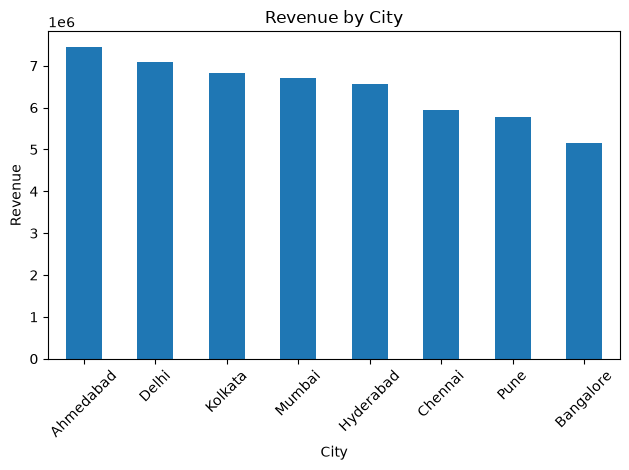

In [74]:
city_revenue = city_revenue.sort_values(ascending=False)

city_revenue.plot(kind="bar", title="Revenue by City")

plt.xlabel("City")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Chart 2: Category Contribution

**Objective:** To visualize the percentage contribution of each product category to the total revenue.

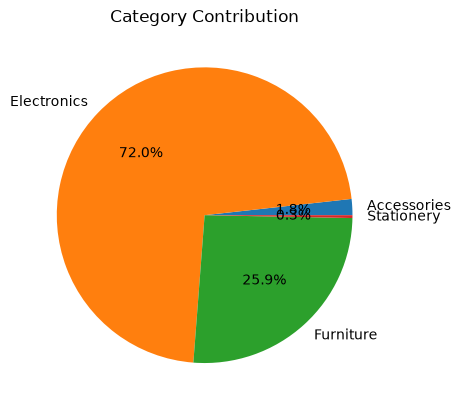

In [75]:
category_revenue.plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Category Contribution"
)

plt.ylabel("")
plt.show()

### Chart 3: Monthly Sales Trend

**Objective:** To visualize monthly revenue changes and identify sales trends over time using a line chart.

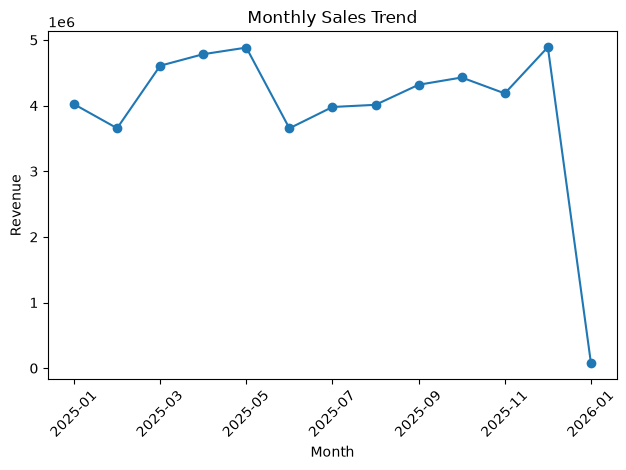

In [76]:
monthly_revenue.index = monthly_revenue.index.astype(str)

monthly_revenue.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Saving cleaned dataset 

In [77]:
df.to_csv("cleaned_sales_data.csv", index=False)


### 1: Top 3 Products by Revenue

**Objective:** To identify the three products that generate the highest total revenue.

In [78]:
product_revenue = df.groupby("Product")["Revenue"].sum()

top_3_products = product_revenue.sort_values(ascending=False).head(3)

print(top_3_products)

Product
Laptop     27105144.0
Sofa        8106368.0
Printer     4966315.0
Name: Revenue, dtype: float64


### 2: Average Order Value (AOV)

**Objective:** To calculate the average revenue generated per order.

In [79]:
total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Total Revenue:", total_revenue)
print("Average Order Value:", round(average_order_value, 2))

Total Orders: 1999
Total Revenue: 51500062.0
Average Order Value: 25762.91


### Importing sqlite3 to perform sql queries

In [80]:
import sqlite3

conn = sqlite3.connect(":memory:")

df.to_sql("sales", conn, index=False, if_exists="replace")

print("Sales data loaded into SQLite successfully!")

Sales data loaded into SQLite successfully!


In [4]:
import pandas as pd

df = pd.read_csv("cleaned_sales_data.csv")

print(df.shape)
print(df.head())

(1999, 8)
   Order_ID        Date   Product     Category       City  Quantity  Price  \
0      1001  2025-02-19   Printer  Electronics    Kolkata       3.0   9591   
1      1002  2025-08-08       Pen   Stationery  Hyderabad       5.0    318   
2      1003  2025-07-28     Mouse  Electronics    Chennai       1.0    697   
3      1004  2025-08-15     Chair    Furniture  Ahmedabad       1.0   3410   
4      1006  2025-10-20  Notebook   Stationery  Ahmedabad       4.0    244   

   Revenue  
0  28773.0  
1   1590.0  
2    697.0  
3   3410.0  
4    976.0  


In [5]:
import sqlite3

conn = sqlite3.connect(":memory:")
df.to_sql("sales", conn, index=False, if_exists="replace")

print("Sales data loaded successfully!")

Sales data loaded successfully!


### SQL Query 1: Total Revenue by Product

**Objective:** To calculate the total revenue generated by each product and arrange the products in descending order of revenue.

**SQL Concepts Used:** `SELECT`, `SUM()`, `GROUP BY`, `ORDER BY`, and `DESC`.

In [6]:
query = """
SELECT Product, SUM(Revenue) AS Total_Revenue
FROM sales
GROUP BY Product
ORDER BY Total_Revenue DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

     Product  Total_Revenue
0     Laptop     27105144.0
1       Sofa      8106368.0
2    Printer      4966315.0
3    Monitor      4088814.0
4      Table      3190192.0
5      Chair      2047224.0
6        Bag       697187.0
7   Keyboard       656757.0
8      Mouse       276320.0
9     Bottle       208582.0
10  Notebook        95422.0
11       Pen        61737.0


### SQL Query 2: Total Revenue by City

**Objective:** To calculate the total revenue generated by each city and identify the best-performing cities.

**SQL Concepts Used:** `SELECT`, `SUM()`, `GROUP BY`, `ORDER BY`, and `DESC`.

In [7]:
query = """
SELECT City, SUM(Revenue) AS Total_Revenue
FROM sales
GROUP BY City
ORDER BY Total_Revenue DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

        City  Total_Revenue
0  Ahmedabad      7449911.0
1      Delhi      7092644.0
2    Kolkata      6819173.0
3     Mumbai      6702803.0
4  Hyderabad      6565333.0
5    Chennai      5944069.0
6       Pune      5764738.0
7  Bangalore      5161391.0


### SQL Query 3: Total Revenue by Category

**Objective:** To calculate and compare the total revenue generated by each product category.

**SQL Concepts Used:** `SELECT`, `SUM()`, `GROUP BY`, `ORDER BY`, and `DESC`.

In [8]:
query = """
SELECT Category, SUM(Revenue) AS Total_Revenue
FROM sales
GROUP BY Category
ORDER BY Total_Revenue DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

      Category  Total_Revenue
0  Electronics     37093350.0
1    Furniture     13343784.0
2  Accessories       905769.0
3   Stationery       157159.0


### SQL Query 4: Monthly Revenue Analysis

**Objective:** To calculate monthly revenue and understand sales trends over time.

**SQL Concepts Used:** `SELECT`, `SUM()`, `GROUP BY`, `ORDER BY`, and SQLite date functions.

In [9]:
query = """
SELECT strftime('%Y-%m', Date) AS Month,
       SUM(Revenue) AS Total_Revenue
FROM sales
GROUP BY strftime('%Y-%m', Date)
ORDER BY Month;
"""

result = pd.read_sql_query(query, conn)

print(result)

      Month  Total_Revenue
0   2025-01      4021909.0
1   2025-02      3655339.0
2   2025-03      4607846.0
3   2025-04      4783602.0
4   2025-05      4884091.0
5   2025-06      3654206.0
6   2025-07      3979183.0
7   2025-08      4012286.0
8   2025-09      4318017.0
9   2025-10      4428577.0
10  2025-11      4185989.0
11  2025-12      4891185.0
12  2026-01        77832.0


### SQL Query 5: Top 5 Products by Quantity Sold

**Objective:** To identify the five most popular products based on the total quantity sold.

**SQL Concepts Used:** `SELECT`, `SUM()`, `GROUP BY`, `ORDER BY`, and `LIMIT`.

In [10]:
query = """
SELECT Product, SUM(Quantity) AS Total_Quantity
FROM sales
GROUP BY Product
ORDER BY Total_Quantity DESC
LIMIT 5;
"""

result = pd.read_sql_query(query, conn)

print(result)

    Product  Total_Quantity
0     Chair           568.0
1      Sofa           537.0
2  Notebook           531.0
3       Bag           529.0
4   Printer           517.0


## Part 6: Business Insights

Based on the sales data analysis, the following business insights were identified:

1. **Top Revenue-Generating Product:** Laptops generated the highest revenue of ₹27,105,144, making them the leading product in terms of revenue contribution.

2. **Best-Selling Product by Quantity:** Chairs recorded the highest quantity sold, with 568 units, indicating strong demand by sales volume.

3. **Best-Performing City:** Ahmedabad generated the highest revenue of ₹7,449,911 among the cities analysed.

4. **Dominant Product Category:** Electronics generated the highest category revenue of ₹37,093,350, significantly exceeding Furniture, Accessories, and Stationery.

5. **Monthly Revenue Variation:** Revenue varied across the months. December 2025 recorded the highest complete-month revenue of ₹4,891,185, while June recorded ₹3,654,206.

6. **Average Order Value:** The average revenue per order was approximately ₹25,762.91, providing a baseline for evaluating order value and future sales performance.

### Conclusion

The analysis indicates that Electronics and Laptops are major revenue contributors, while Chairs lead in quantity sold. Differences across cities and months provide opportunities for more targeted sales planning.

## Part 7: Business Recommendations

Based on the insights obtained from the sales analysis, the following recommendations are proposed:

1. **Prioritise High-Revenue Products:** Maintain adequate Laptop inventory and review pricing, availability, and profit margins to support continued revenue generation.

2. **Promote High-Volume Products:** Use suitable offers or product bundles for Chairs to build on their strong sales volume and encourage additional purchases.

3. **Strengthen Regional Sales Strategies:** Investigate the factors behind Ahmedabad's high revenue and apply successful approaches to lower-performing cities where appropriate.

4. **Focus on Electronics:** Prioritise the Electronics category in inventory planning and marketing while evaluating profitability and customer demand across individual products.

5. **Plan for Seasonal Demand:** Review monthly sales patterns to plan promotions and inventory. Compare complete months only, and investigate the reasons for revenue fluctuations before making seasonal decisions.

6. **Increase Average Order Value:** Test relevant cross-selling, complementary product bundles, and minimum-order promotions to encourage customers to purchase additional items.

### Final Recommendation

The business should focus on high-revenue products, monitor regional and monthly sales patterns, improve order value, and maintain reliable data. Future decisions should also consider product costs and profit margins, since revenue alone does not indicate profitability.